# Classificação - Resposta a Campanha de Marketing Bancário

## 1. Definição do problema

Bancos fazem campanhas de marketing por telefone para oferecer produtos, como o depósito a prazo (uma aplicação em que o cliente deixa o dinheiro guardado por um tempo em troca de juros). Ligar para todos os clientes custa tempo e dinheiro, e a maioria não aceita a oferta. Se o banco souber quais clientes têm mais chance de aceitar, pode focar as ligações neles.

**Pergunta principal:** É possível prever se um cliente vai aceitar a oferta de depósito a prazo da campanha de marketing?

**Tipo de problema:** Classificação, pois a variável alvo tem duas categorias (aceita ou não aceita).

## 2. Apresentação da base de dados

- **Nome:** Bank Marketing (arquivo `bank-full.csv`)
- **Origem:** campanhas de marketing por telefone de um banco de Portugal (2008 a 2010), publicadas no UCI Machine Learning Repository: https://archive.ics.uci.edu/dataset/222/bank+marketing
- **Registros:** 45.211 contatos com clientes
- **Colunas:** 17 (16 variáveis de entrada e 1 variável alvo)

| Coluna original | Nome usado | Significado |
|---|---|---|
| age | idade | idade do cliente |
| job | profissao | tipo de trabalho |
| marital | estado_civil | casado, solteiro ou divorciado |
| education | escolaridade | primário, secundário, superior ou desconhecido |
| default | inadimplente | se tem crédito em atraso (yes/no) |
| balance | saldo | saldo médio anual na conta (euros) |
| housing | financiamento_casa | se tem financiamento imobiliário (yes/no) |
| loan | emprestimo | se tem empréstimo pessoal (yes/no) |
| contact | tipo_contato | celular, telefone fixo ou desconhecido |
| day | dia | dia do mês do último contato |
| month | mes | mês do último contato |
| duration | duracao | duração da última ligação em segundos |
| campaign | qtd_contatos | quantas vezes o cliente foi contatado nesta campanha |
| pdays | dias_ultimo_contato | dias desde o contato da campanha anterior (-1 = nunca foi contatado) |
| previous | contatos_anteriores | quantos contatos foram feitos antes desta campanha |
| poutcome | resultado_anterior | resultado da campanha anterior |
| y | aderiu | **variável alvo**: se o cliente aceitou o depósito a prazo (yes/no) |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# carregando os dados (o arquivo usa ; como separador)
df = pd.read_csv('../dados/bank-full.csv', sep=';')

# renomeando as colunas para facilitar a leitura
df = df.rename(columns={
    'age': 'idade',
    'job': 'profissao',
    'marital': 'estado_civil',
    'education': 'escolaridade',
    'default': 'inadimplente',
    'balance': 'saldo',
    'housing': 'financiamento_casa',
    'loan': 'emprestimo',
    'contact': 'tipo_contato',
    'day': 'dia',
    'month': 'mes',
    'duration': 'duracao',
    'campaign': 'qtd_contatos',
    'pdays': 'dias_ultimo_contato',
    'previous': 'contatos_anteriores',
    'poutcome': 'resultado_anterior',
    'y': 'aderiu'
})

print('Linhas:', df.shape[0])
print('Colunas:', df.shape[1])

Linhas: 45211
Colunas: 17


## 3. Análise exploratória dos dados

In [3]:
# primeiras linhas
df.head()

,idade,profissao,estado_civil,escolaridade,inadimplente,saldo,financiamento_casa,emprestimo,tipo_contato,dia,mes,duracao,qtd_contatos,dias_ultimo_contato,contatos_anteriores,resultado_anterior,aderiu
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [4]:
# tipos de dados
df.dtypes

idade                  int64
profissao                str
estado_civil             str
escolaridade             str
inadimplente             str
saldo                  int64
financiamento_casa       str
emprestimo               str
tipo_contato             str
dia                    int64
mes                      str
duracao                int64
qtd_contatos           int64
dias_ultimo_contato    int64
contatos_anteriores    int64
resultado_anterior       str
aderiu                   str
dtype: object

In [5]:
# valores ausentes
df.isnull().sum()

idade                  0
profissao              0
estado_civil           0
escolaridade           0
inadimplente           0
saldo                  0
financiamento_casa     0
emprestimo             0
tipo_contato           0
dia                    0
mes                    0
duracao                0
qtd_contatos           0
dias_ultimo_contato    0
contatos_anteriores    0
resultado_anterior     0
aderiu                 0
dtype: int64

In [6]:
# registros duplicados
print('Duplicados:', df.duplicated().sum())

Duplicados: 0


In [7]:
# estatisticas basicas das colunas numericas
df.describe().round(2)

,idade,saldo,dia,duracao,qtd_contatos,dias_ultimo_contato,contatos_anteriores
count,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00,45211.00
mean,40.94,1362.27,15.81,258.16,2.76,40.20,0.58
std,10.62,3044.77,8.32,257.53,3.10,100.13,2.30
min,18.00,-8019.00,1.00,0.00,1.00,-1.00,0.00
25%,33.00,72.00,8.00,103.00,1.00,-1.00,0.00
50%,39.00,448.00,16.00,180.00,2.00,-1.00,0.00
75%,48.00,1428.00,21.00,319.00,3.00,-1.00,0.00
max,95.00,102127.00,31.00,4918.00,63.00,871.00,275.00


In [8]:
# quantidade de valores 'unknown' em cada coluna de texto
colunas_texto = ['profissao', 'estado_civil', 'escolaridade', 'inadimplente', 'financiamento_casa',
                 'emprestimo', 'tipo_contato', 'mes', 'resultado_anterior']
for coluna in colunas_texto:
    print(coluna, '->', (df[coluna] == 'unknown').sum())

profissao -> 288
estado_civil -> 0
escolaridade -> 1857
inadimplente -> 0
financiamento_casa -> 0
emprestimo -> 0
tipo_contato -> 13020
mes -> 0
resultado_anterior -> 36959


In [9]:
# porcentagem de clientes que nunca foram contatados antes
print('Nunca contatados antes:', round((df['dias_ultimo_contato'] == -1).mean() * 100, 1), '%')

Nunca contatados antes: 81.7 %


aderiu
no     39922
yes     5289
Name: count, dtype: int64

aderiu
no     0.883
yes    0.117
Name: proportion, dtype: float64


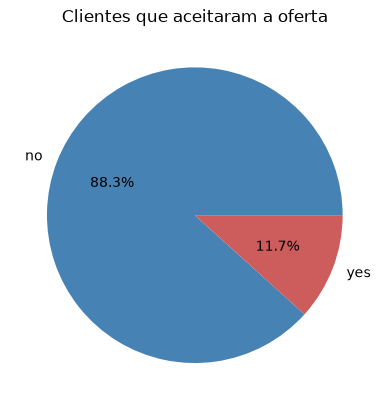

In [10]:
# distribuicao da variavel alvo
print(df['aderiu'].value_counts())
print()
print(df['aderiu'].value_counts(normalize=True).round(3))

df['aderiu'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['steelblue', 'indianred'])
plt.title('Clientes que aceitaram a oferta')
plt.ylabel('')
plt.show()

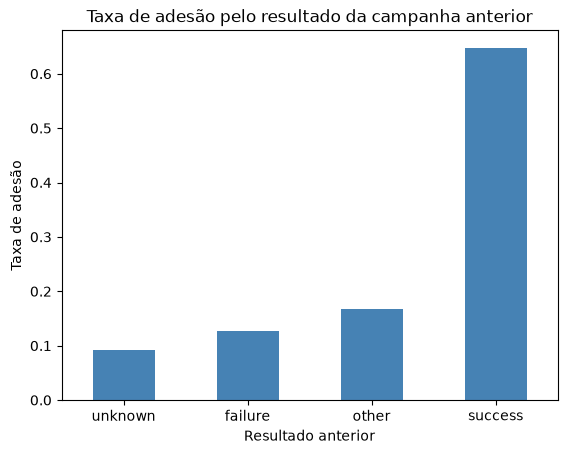

In [11]:
# taxa de adesao pelo resultado da campanha anterior
taxa_anterior = df.groupby('resultado_anterior')['aderiu'].apply(lambda x: (x == 'yes').mean())

taxa_anterior.sort_values().plot(kind='bar', color='steelblue')
plt.title('Taxa de adesão pelo resultado da campanha anterior')
plt.xlabel('Resultado anterior')
plt.ylabel('Taxa de adesão')
plt.xticks(rotation=0)
plt.show()

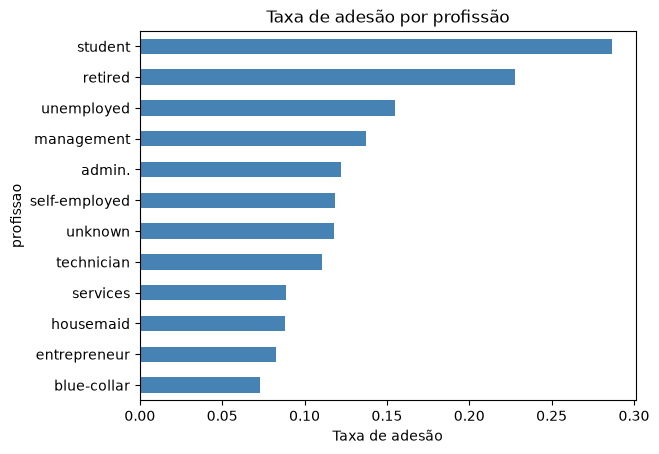

In [12]:
# taxa de adesao por profissao
taxa_profissao = df.groupby('profissao')['aderiu'].apply(lambda x: (x == 'yes').mean())

taxa_profissao.sort_values().plot(kind='barh', color='steelblue')
plt.title('Taxa de adesão por profissão')
plt.xlabel('Taxa de adesão')
plt.show()

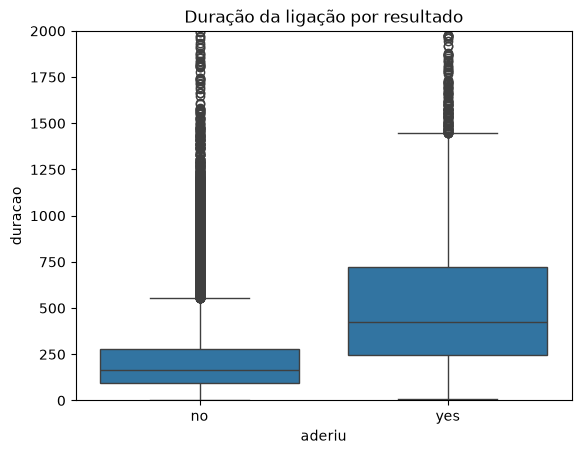

In [13]:
# duracao da ligacao por resultado
sns.boxplot(data=df, x='aderiu', y='duracao')
plt.title('Duração da ligação por resultado')
plt.ylim(0, 2000)
plt.show()

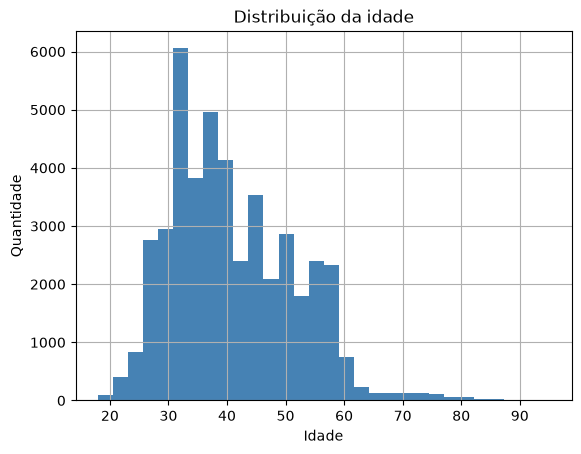

In [14]:
# histograma da idade
df['idade'].hist(bins=30, color='steelblue')
plt.title('Distribuição da idade')
plt.xlabel('Idade')
plt.ylabel('Quantidade')
plt.show()

**O que a análise mostrou:**

- A base tem 45.211 registros, sem valores ausentes declarados e sem duplicados.
- Porém várias colunas usam o texto "unknown" para informação desconhecida: 36.959 em resultado anterior, 13.020 em tipo de contato, 1.857 em escolaridade e 288 em profissão.
- 81,7% dos clientes nunca tinham sido contatados em campanhas anteriores.
- A base é bem **desbalanceada**: só 11,7% dos clientes aceitaram a oferta.
- O **resultado da campanha anterior** influencia muito: clientes que aceitaram na campanha anterior (success) aceitaram de novo em 65% dos casos, contra 9% de quem não tem histórico.
- **Estudantes (29%) e aposentados (23%)** são as profissões com maior taxa de adesão. Trabalhadores braçais (blue-collar) têm a menor (7%).
- A **duração da ligação** é muito maior para quem aceitou (mediana de 426 segundos contra 164). Isso é esperado, porque quem aceita fica mais tempo na linha para fechar o negócio, mas essa informação só existe depois da ligação.

## 4. Preparação dos dados

Decisões tomadas:

1. **Duplicados e ausentes:** a base não tem registros duplicados nem valores ausentes.
2. **Remoção da coluna `duracao`:** a duração da ligação só é conhecida depois que a ligação termina, e aí o banco já sabe se o cliente aceitou ou não. Usar essa coluna faria o modelo parecer muito bom, mas ele não serviria para escolher para quem ligar antes da ligação. A própria documentação da base recomenda descartar essa coluna para um modelo realista.
3. **Valores 'unknown':** foram mantidos como uma categoria própria. Em `resultado_anterior` e `tipo_contato` eles representam a maioria dos casos e têm significado (cliente que não participou de campanha anterior). Em `profissao` e `escolaridade` são poucos casos e remover as linhas faria perder dados sem necessidade.
4. **Coluna `dias_ultimo_contato`:** o valor -1 significa "nunca foi contatado", e isso acontece em 82% dos casos. Como -1 não é um número de dias de verdade, a coluna foi trocada por `contato_anterior` (1 = já foi contatado antes, 0 = nunca).
5. **Colunas yes/no:** transformadas em 1 e 0.
6. **Variáveis categóricas:** profissão, estado civil, escolaridade, tipo de contato, mês e resultado anterior foram transformadas com **one-hot encoding**.
7. **Treino e teste:** 80% treino e 20% teste com `stratify`, porque só 11,7% dos clientes aceitaram.
8. **Padronização:** `StandardScaler`, porque o saldo vai de -8 mil a 100 mil euros enquanto outras colunas são 0 ou 1.

In [15]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# removendo a duracao da ligacao
df = df.drop(columns='duracao')

# trocando dias_ultimo_contato por uma coluna que indica se ja foi contatado
df['contato_anterior'] = (df['dias_ultimo_contato'] != -1).astype(int)
df = df.drop(columns='dias_ultimo_contato')

# transformando as colunas yes/no em 1/0
for coluna in ['inadimplente', 'financiamento_casa', 'emprestimo', 'aderiu']:
    df[coluna] = (df[coluna] == 'yes').astype(int)

# one-hot encoding
df = pd.get_dummies(df, columns=['profissao', 'estado_civil', 'escolaridade',
                                 'tipo_contato', 'mes', 'resultado_anterior'], dtype=int)

print('Colunas depois da preparação:', df.shape[1])
df.head()

Colunas depois da preparação: 48


,idade,inadimplente,saldo,financiamento_casa,emprestimo,dia,qtd_contatos,contatos_anteriores,aderiu,contato_anterior,...,mes_jun,mes_mar,mes_may,mes_nov,mes_oct,mes_sep,resultado_anterior_failure,resultado_anterior_other,resultado_anterior_success,resultado_anterior_unknown
0,58,0,2143,1,0,5,1,0,0,0,...,0,0,1,0,0,0,0,0,0,1
1,44,0,29,1,0,5,1,0,0,0,...,0,0,1,0,0,0,0,0,0,1
2,33,0,2,1,1,5,1,0,0,0,...,0,0,1,0,0,0,0,0,0,1
3,47,0,1506,1,0,5,1,0,0,0,...,0,0,1,0,0,0,0,0,0,1
4,33,0,1,0,0,5,1,0,0,0,...,0,0,1,0,0,0,0,0,0,1


In [16]:
# separando entradas (X) e alvo (y)
X = df.drop(columns='aderiu')
y = df['aderiu']

# dividindo em treino e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# padronizando
scaler = StandardScaler()
X_treino_pad = scaler.fit_transform(X_treino)
X_teste_pad = scaler.transform(X_teste)

print('Treino:', X_treino_pad.shape)
print('Teste:', X_teste_pad.shape)
print()
print('Proporção de adesão no treino:', round(y_treino.mean(), 3))
print('Proporção de adesão no teste:', round(y_teste.mean(), 3))

Treino: (36168, 47)
Teste: (9043, 47)

Proporção de adesão no treino: 0.117
Proporção de adesão no teste: 0.117


## 5. Escolha dos modelos

Foram usados os mesmos 5 modelos de classificação dos outros problemas:

- **Regressão Logística:** modelo simples e rápido, muito usado em marketing para estimar a probabilidade de resposta de cada cliente.
- **KNN:** compara o cliente com os 15 clientes mais parecidos do treino.
- **Árvore de Decisão:** gera regras fáceis de explicar para a equipe de marketing. Limitada a profundidade 5 para não decorar os dados.
- **Random Forest:** conjunto de árvores, costuma funcionar bem com muitas colunas categóricas como nesta base.
- **SVM:** procura a melhor fronteira entre os clientes que aceitam e os que não aceitam.

## 6. Treinamento dos modelos

- **Dados de treino:** 36.168 contatos (80%)
- **Dados de teste:** 9.043 contatos (20%)

Cada modelo aprende com os dados de treino (`fit`) e depois faz as previsões nos dados de teste (`predict`). É a maior base do trabalho, então o SVM demora alguns minutos para treinar.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

modelos = {
    'Regressão Logística': LogisticRegression(random_state=42, max_iter=1000),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'Árvore de Decisão': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(random_state=42)
}

# treinando cada modelo e guardando as previsoes no teste
previsoes = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino_pad, y_treino)
    previsoes[nome] = modelo.predict(X_teste_pad)
    print(nome, '- treinado')

Regressão Logística - treinado


KNN - treinado
Árvore de Decisão - treinado


Random Forest - treinado


SVM - treinado


## 7. Avaliação dos modelos

Métricas utilizadas:

- **Acurácia:** porcentagem total de acertos.
- **Precisão:** dos clientes que o modelo indicou que vão aceitar, quantos realmente aceitaram. Uma precisão alta significa menos ligações desperdiçadas.
- **Recall:** dos clientes que realmente aceitaram, quantos o modelo encontrou. Um recall alto significa menos clientes interessados deixados de fora.
- **F1-score:** equilíbrio entre precisão e recall.
- **Matriz de confusão:** mostra os acertos e erros de cada classe.

Como 88% dos clientes recusam a oferta, um modelo que sempre dissesse "não aceita" teria 88% de acurácia. Por isso a análise vai focar mais na precisão, no recall e no F1-score.

In [18]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

resultados = []
for nome, y_prev in previsoes.items():
    resultados.append({
        'Modelo': nome,
        'Acurácia': accuracy_score(y_teste, y_prev),
        'Precisão': precision_score(y_teste, y_prev),
        'Recall': recall_score(y_teste, y_prev),
        'F1-score': f1_score(y_teste, y_prev)
    })

tabela = pd.DataFrame(resultados).sort_values('F1-score', ascending=False)
tabela.round(3)

,Modelo,Acurácia,Precisão,Recall,F1-score
3,Random Forest,0.893,0.613,0.223,0.327
1,KNN,0.892,0.603,0.216,0.318
4,SVM,0.893,0.637,0.202,0.307
0,Regressão Logística,0.893,0.662,0.180,0.283
2,Árvore de Decisão,0.893,0.653,0.180,0.282


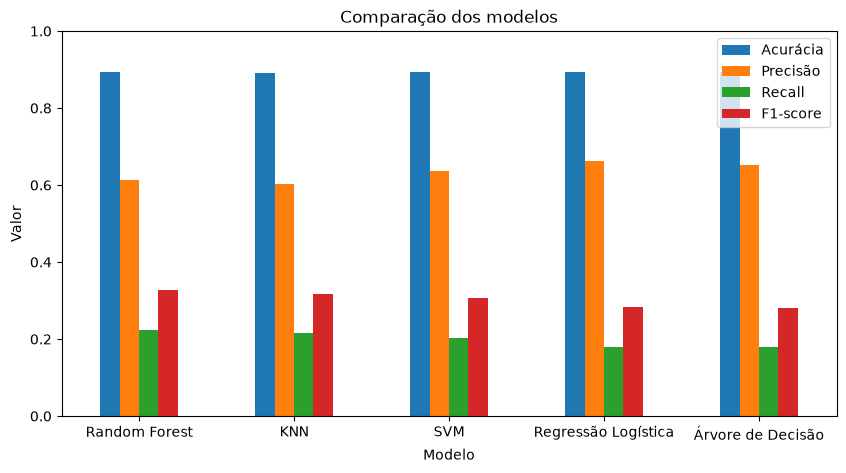

In [19]:
# comparando os modelos em grafico
tabela.set_index('Modelo').plot(kind='bar', figsize=(10, 5))
plt.title('Comparação dos modelos')
plt.ylabel('Valor')
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc='upper right')
plt.show()

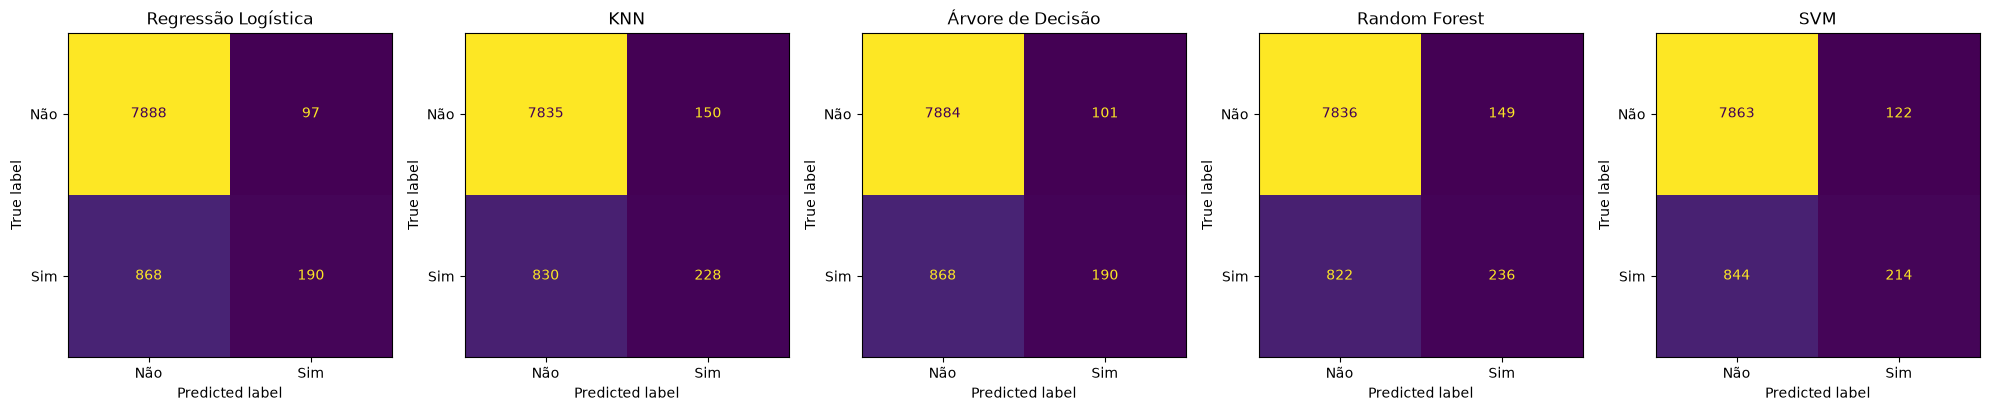

In [20]:
# matriz de confusao de cada modelo
fig, eixos = plt.subplots(1, 5, figsize=(20, 4))
for eixo, (nome, y_prev) in zip(eixos, previsoes.items()):
    matriz = confusion_matrix(y_teste, y_prev)
    ConfusionMatrixDisplay(matriz, display_labels=['Não', 'Sim']).plot(ax=eixo, colorbar=False)
    eixo.set_title(nome)
plt.tight_layout()
plt.show()

In [21]:
# relatorio completo do melhor modelo
melhor_nome = tabela.iloc[0]['Modelo']
print('Melhor modelo pelo F1-score:', melhor_nome)
print()
print(classification_report(y_teste, previsoes[melhor_nome], target_names=['Não aceitou', 'Aceitou']))

Melhor modelo pelo F1-score: Random Forest

              precision    recall  f1-score   support

 Não aceitou       0.91      0.98      0.94      7985
     Aceitou       0.61      0.22      0.33      1058

    accuracy                           0.89      9043
   macro avg       0.76      0.60      0.63      9043
weighted avg       0.87      0.89      0.87      9043



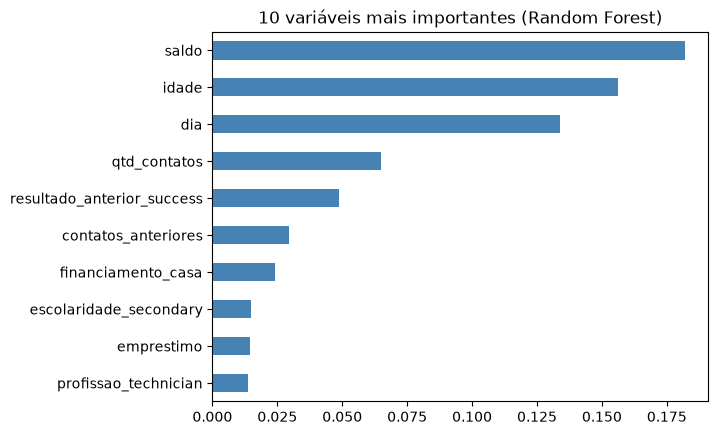

In [22]:
# variaveis mais importantes para o random forest
importancia = pd.Series(modelos['Random Forest'].feature_importances_, index=X.columns)
importancia.sort_values().tail(10).plot(kind='barh', color='steelblue')
plt.title('10 variáveis mais importantes (Random Forest)')
plt.show()

**Interpretação dos resultados:**

- Todos os modelos tiveram praticamente a mesma acurácia (89,2% a 89,3%), que é quase igual a dizer sempre "não aceita" (88,3%). Por isso a acurácia não ajuda a escolher o modelo aqui.
- O melhor modelo pelo F1-score foi o **Random Forest** (F1 de 0,327), seguido do KNN (0,318).
- A **precisão** ficou em torno de 60% a 66% em todos os modelos. Isso quer dizer que, dos clientes que o modelo indica para ligar, cerca de 6 em cada 10 aceitam. Sem o modelo, ligando para qualquer um, só cerca de 1 em cada 10 aceita. Então o modelo **aumenta bastante a eficiência das ligações**.
- O problema é o **recall** baixo: o Random Forest encontrou só 236 dos 1.058 clientes que aceitaram (22,3%). Muitos clientes interessados ficariam sem receber a ligação.
- Sem a duração da ligação, os modelos têm pouca informação forte para separar as classes, o que explica o desempenho limitado.
- No gráfico de importância, saldo, idade e dia do contato aparecem no topo. Vale lembrar que o Random Forest tende a dar mais importância para colunas numéricas com muitos valores diferentes, então o resultado anterior (success) pode ser mais relevante do que parece no gráfico, como mostrou a análise exploratória.

## 8. Exemplo de previsão

Usando o melhor modelo para prever 6 clientes do conjunto de teste (3 que recusaram e 3 que aceitaram) e comparando com o que realmente aconteceu.

In [23]:
melhor_modelo = modelos[melhor_nome]

# pegando 3 clientes que recusaram e 3 que aceitaram
indices = list(y_teste[y_teste == 0].index[:3]) + list(y_teste[y_teste == 1].index[:3])
exemplos = X_teste.loc[indices]
exemplos_pad = scaler.transform(exemplos)

resultado = exemplos[['idade', 'saldo', 'qtd_contatos', 'contato_anterior', 'resultado_anterior_success']].copy()
resultado['previsto'] = melhor_modelo.predict(exemplos_pad)
resultado['real'] = y_teste.loc[indices].values
resultado

,idade,saldo,qtd_contatos,contato_anterior,resultado_anterior_success,previsto,real
1392,40,640,2,0,0,0,0
7518,44,378,2,0,0,0,0
12007,31,356,5,0,0,0,0
43965,64,109,1,1,1,1,1
41933,31,6281,1,1,0,0,1
34965,49,99,2,1,0,0,1


Nos 6 exemplos, o modelo acertou os 3 clientes que recusaram e 1 dos 3 que aceitaram. O cliente que ele acertou tinha aceitado a campanha anterior, o que mostra que o histórico é um sinal forte para o modelo.

## 9. Conclusão

**Resumo:** o objetivo foi prever se um cliente vai aceitar a oferta de depósito a prazo em uma campanha de marketing por telefone, usando dados pessoais, financeiros e o histórico de contatos de 45.211 clientes. Foram testados 5 modelos de classificação.

**Principais descobertas:** quem já aceitou uma campanha anterior tem muito mais chance de aceitar de novo. Estudantes e aposentados respondem melhor às campanhas. A coluna de duração da ligação foi removida porque só é conhecida depois da ligação e deixaria o modelo irreal.

**Desempenho:** o melhor modelo foi o Random Forest, com F1-score de 0,327, precisão de 0,61 e recall de 0,22. A resposta para a pergunta é **sim, em parte**: o modelo não encontra a maioria dos clientes que aceitariam, mas os clientes que ele indica têm uma chance cerca de 5 vezes maior de aceitar do que um cliente escolhido ao acaso.

**Limitações:**
- Base muito desbalanceada (só 11,7% de adesão), o que prejudica o recall.
- Sem a duração da ligação, sobram poucas variáveis com relação forte com a resposta.
- Muitos valores "unknown", principalmente no resultado anterior e no tipo de contato.
- Os dados são de 2008 a 2010, época de crise financeira em Portugal, então o comportamento dos clientes pode ser diferente hoje.

**Melhorias futuras:**
- Usar `class_weight='balanced'` ou técnicas de balanceamento para aumentar o recall.
- Em vez de usar só a resposta sim/não, ordenar os clientes pela probabilidade de aceitar e ligar primeiro para os de maior probabilidade.
- Ajustar os hiperparâmetros com `GridSearchCV` e usar validação cruzada.
- Testar a versão `bank-additional` da base, que tem indicadores econômicos (como taxa de juros) que podem ajudar.

**Opinião crítica:** neste problema o Machine Learning faz bastante sentido, porque o custo de errar é baixo (no pior caso o banco faz uma ligação a mais ou a menos) e o ganho de focar nos clientes certos é grande. Mesmo com recall baixo, o modelo já seria útil para priorizar as ligações. Um cuidado importante é não usar informações do futuro, como a duração da ligação, que dariam um resultado ótimo no notebook, mas que não funcionaria na prática.